# Data, turnout, and census

From `FINDINGS.md`:

> Preliminary Statement of the Vote, Report 9, published November 8, 2026 at 5:00 p.m. Phoenix (4:00 p.m. Pacific). Certification is due December 3. Every figure is stamped with that report. Totals below are San Francisco votes only.
>
> The subject is where in the city each contest ran strong, and which precinct characteristics move with that pattern. The contests are the governor’s race inside the city, CA-11, and Measures B, G, I, and D. Each section has the citywide result, the precinct and supervisor-district geography, and the census comparison.
>
> A share is the named side divided by the two-candidate vote, or by Yes plus No. Among precincts with at least 50 ballots, the 10th, 50th, and 90th percentiles are given as a range. District figures are vote-weighted. A correlation describes precincts with at least 50 ballots and with group quarters under 25 percent of the 2020 population. It describes the precinct. It does not say how the people in a demographic group voted.
>
> The precinct map is DataSF’s 2022 shapes: 514 polygons, all 514 matched to the Statement of the Vote, reconciled to the citywide totals with a difference of zero. Districts come from the Department of Elections crosswalk of August 17, 2026. Four precincts have no registered voters and are left off the maps: Angel Island, Alameda Island, and two small inland precincts, 9901 in the Outer Mission and 9902 in Portola. Party registration is citywide only. The Department’s page lists 541,778 registered voters (337,357 Democratic, 40,457 Republican, 141,468 no party preference or unknown), which is a different vintage from the 535,608 on the Statement of the Vote, so it is recorded and not mapped.
>
> Turnout is 64.01 percent (342,844 of 535,608). Mail is 304,904 ballots, 88.93 percent, and election day is 37,940. Precinct turnout runs from 47.8 percent to 66.1 percent to 76.2 percent, higher in the north, the center, and the west, and lower in the southeast. It rises with the bachelor’s-degree share of the precinct (r = 0.80) and with the non-Hispanic white share (r = 0.79).
>
> Census characteristics are 2020 block counts, or ACS 2020–2024 counts spread onto those blocks. All 873,965 people in the 2020 county count are assigned. A precinct line cuts 33 blocks, holding 0.3 percent of the population. On every other block, the Census internal point and the land-area majority name the same precinct. Citywide, bachelor’s degree or higher is 60 percent of adults 25 and older, renters are 62 percent of occupied units, foreign-born residents are 34 percent, and households at $150,000 or more are 48 percent.

Every number below is computed from the files in `source/`. Run the setup cell first, then the rest in order (Runtime → Run all). The last cell lists each number the memo section quotes next to the value computed here, and stops with an error if any differ.

In [1]:
# Run this cell first. It finds the sf-2026-drive folder (on Google Drive in Colab, or on
# this computer) and loads the shared code in notebooks/sf2026.py.
import subprocess
import sys
from pathlib import Path

try:
    import geopandas  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)

FOLDER_NAME = "sf-2026-drive"


def is_root(path: Path) -> bool:
    return (path / "source" / "precinct_results.csv").exists() and (path / "notebooks" / "sf2026.py").exists()


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if is_root(candidate):
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError("Open this notebook from inside the sf-2026-drive folder.")
    drive.mount("/content/drive")
    bases = [Path("/content/drive/MyDrive"), Path("/content/drive/Shareddrives")]
    for base in bases:
        if is_root(base / FOLDER_NAME):
            return base / FOLDER_NAME
    for base in bases:
        if base.exists():
            for helper in base.rglob("sf2026.py"):
                if is_root(helper.parent.parent):
                    return helper.parent.parent
    raise FileNotFoundError(
        f"Could not find the {FOLDER_NAME} folder on Drive. If you renamed it, set FOLDER_NAME above."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import pandas as pd
import sf2026 as sf

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
data = sf.load(ROOT)
check = sf.MemoCheck()
print(f"Using the {ROOT.name} folder: {len(data)} precincts")

Using the sf-2026-drive folder: 514 precincts


## The precinct data

The shapes, the Statement of the Vote, and the citywide totals have to agree before
anything else is worth reading. `reconciliation.csv` is the check the analysis ran
against the full Statement of the Vote workbook. The second table below repeats it
here for the featured contests, using only the files in `source/`.

In [2]:
results = pd.read_csv(ROOT / "source" / "precinct_results.csv")
reconciliation = pd.read_csv(ROOT / "source" / "reconciliation.csv")
shapes, rows = set(data["precinct_id"]), set(results["precinct_id"])
check.number("Precinct polygons", 514, len(data), 0)
check.fact("Polygons matched to the Statement of the Vote", "all 514",
           f"{len(shapes & rows)} matched, {len(shapes ^ rows)} unmatched",
           shapes == rows and len(shapes) == 514)
check.number("Largest gap between precinct sums and citywide totals, all contests",
             0, reconciliation["difference"].abs().max(), 0)
reconciliation.head()

,contest,choice,precinct_votes,electionwide_votes,cumulative_votes,difference
0,ASSESSOR-RECORDER,JOAQUIN TORRES,230969,230969,0,0
1,ASSESSOR-RECORDER,Write-in,233,233,0,0
2,"ASSOCIATE JUSTICE COURT OF APPEAL, FIRST DISTR...",NO,27852,27852,0,0
3,"ASSOCIATE JUSTICE COURT OF APPEAL, FIRST DISTR...",YES,205018,205018,0,0
4,"ASSOCIATE JUSTICE COURT OF APPEAL, FIRST DISTR...",NO,27903,27903,0,0


In [3]:
trend = pd.read_csv(ROOT / "source" / "citywide_trend.csv")
report9 = trend[trend["report"] == trend["report"].max()]
contests = {
    "hilton": ("GOVERNOR", "STEVE HILTON"),
    "becerra": ("GOVERNOR", "XAVIER BECERRA"),
    "chan": ("UNITED STATES REPRESENTATIVE, DISTRICT 11", "CONNIE CHAN"),
    "wiener": ("UNITED STATES REPRESENTATIVE, DISTRICT 11", "SCOTT WIENER"),
}
for measure in sf.local_measures(data):
    slug = measure.lower().replace(" ", "_")
    contests[f"{slug}__yes"] = (measure, "YES")
    contests[f"{slug}__no"] = (measure, "NO")
rows = []
for column, (contest, choice) in contests.items():
    official = report9[(report9["contest"] == contest) & (report9["choice"] == choice)]["votes"].sum()
    rows.append({"column": column, "precinct sum": int(data[column].sum()), "citywide report": int(official)})
sums = pd.DataFrame(rows)
sums["difference"] = sums["precinct sum"] - sums["citywide report"]
check.number("Largest gap for the featured contests, from source/ alone", 0, sums["difference"].abs().max(), 0)
sums

,column,precinct sum,citywide report,difference
0,hilton,50784,50784,0
1,becerra,280594,280594,0
2,chan,136435,136435,0
3,wiener,157394,157394,0
4,measure_a__yes,216795,216795,0
5,measure_a__no,101191,101191,0
6,measure_b__yes,164430,164430,0
7,measure_b__no,149904,149904,0
8,measure_c__yes,260103,260103,0
9,measure_c__no,58305,58305,0


## Precincts left off the maps

In [4]:
zero = data.loc[data["registered"].fillna(0) == 0, ["precinct_id", "Neighborhood", "Supervisorial"]]
check.fact("Precincts with no registered voters", "9901, 9902, 9903, 9904",
           ", ".join(str(i) for i in sorted(zero["precinct_id"])),
           set(zero["precinct_id"]) == {9901, 9902, 9903, 9904})
zero

,precinct_id,Neighborhood,Supervisorial
99,9902,PORTOLA,9
101,9901,OUTER MISSION,8
413,9903,ALAMEDA ISLAND,6
513,9904,ANGEL ISLAND,6


## Party registration

The Department's registration-by-party page is citywide only, and it is a different
vintage from the Statement of the Vote.

In [5]:
party = pd.read_csv(ROOT / "source" / "citywide_party.csv").set_index("group")["registered"]
check.number("Registered voters, party page", 541778, party["Total Registration"], 0)
check.number("Democratic", 337357, party["Democratic"], 0)
check.number("Republican", 40457, party["Republican"], 0)
check.number("No party preference or unknown", 141468, party["No Party Preference/Unknown"], 0)
check.number("Registered voters, Statement of the Vote", 535608, data["registered"].sum(), 0)
party.to_frame()

,registered
group,
Total Registration,541778
Military and Overseas,11847
American Independent,12835
Democratic,337357
Green,3429
Libertarian,3220
Peace and Freedom,3012
Republican,40457
No Party Preference/Unknown,141468


## Turnout and mail

In [6]:
ballots, registered, mail = data["ballots"].sum(), data["registered"].sum(), data["mail_ballots"].sum()
check.number("Turnout, percent", 64.01, 100 * ballots / registered, 2)
check.number("Ballots counted", 342844, ballots, 0)
check.number("Mail ballots", 304904, mail, 0)
check.number("Mail share, percent", 88.93, 100 * mail / ballots, 2)
check.number("Election-day ballots", 37940, ballots - mail, 0)

share = data["ballots"] / data["registered"].where(data["registered"] > 0)
enough = data["ballots"] >= sf.MIN_BALLOTS
for name, memo, value in zip(["10th", "50th", "90th"], [47.8, 66.1, 76.2], sf.percentile_range(share, enough)):
    check.number(f"Precinct turnout, {name} percentile", memo, value)

grouped = data.groupby("Supervisorial")[["ballots", "registered"]].sum()
(100 * grouped["ballots"] / grouped["registered"]).round(1).to_frame("Turnout by supervisor district, percent")

,"Turnout by supervisor district, percent"
Supervisorial,
1,70.10
2,67.90
3,60.40
4,65.40
5,61.40
6,56.80
7,69.80
8,76.10
9,64.20


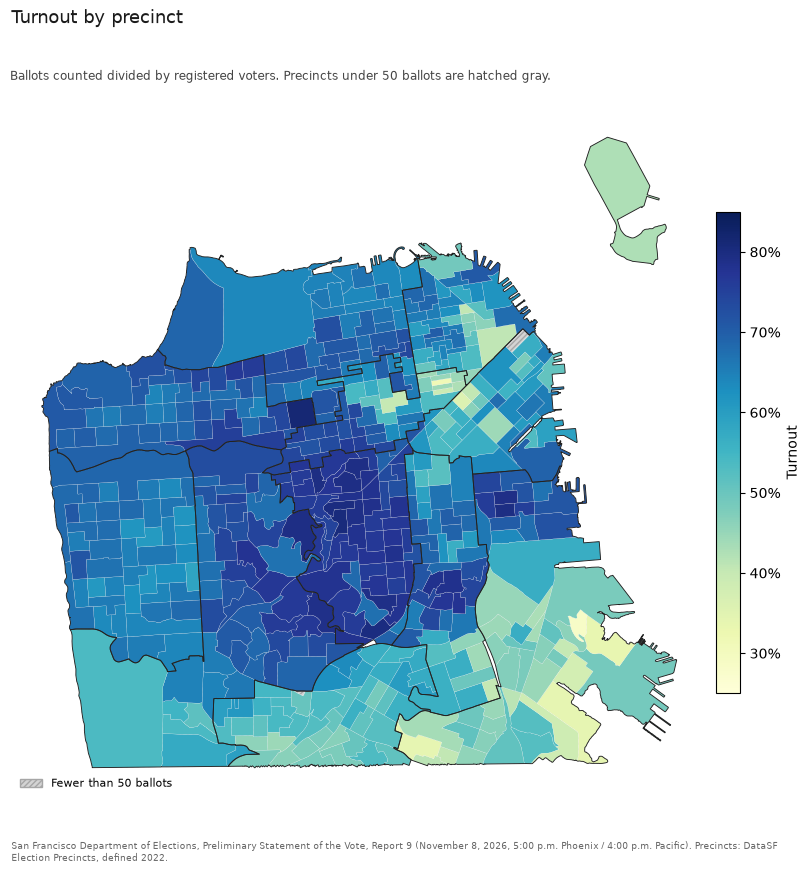

In [7]:
sf.rate_map(data, share, data["ballots"], "Turnout by precinct",
            "Ballots counted divided by registered voters. Precincts under 50 ballots are hatched gray.",
            "Turnout", cmap="YlGnBu", diverging=False, limits=(0.25, 0.85))

,r
Non-Hispanic Asian,-0.46
Non-Hispanic white,0.79
Hispanic,-0.43
Bachelor's degree or higher,0.80
Renters,-0.12
"Households at $150,000+",0.65
Foreign born,-0.63


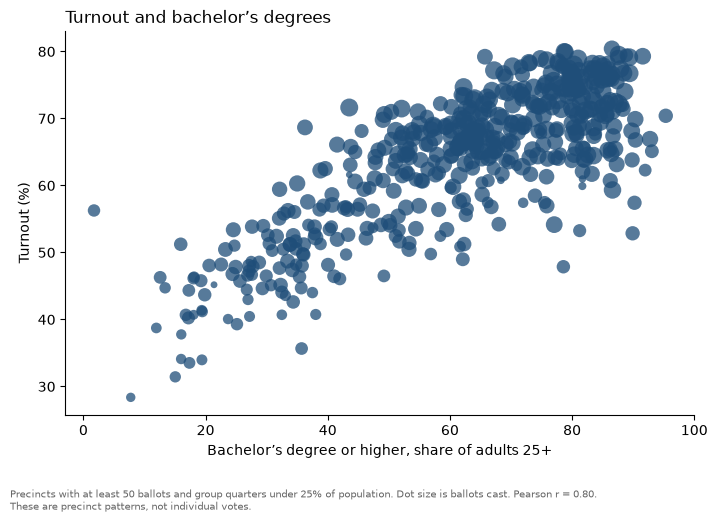

In [8]:
r = sf.census_correlations(data, share, sf.census_frame(data))
display(r.to_frame())
check.number("Correlation with Bachelor's degree or higher", 0.8, r["Bachelor's degree or higher"], 2)
check.number("Correlation with Non-Hispanic white", 0.79, r["Non-Hispanic white"], 2)
keep = sf.census_frame(data)
sf.census_scatter(data[keep].assign(share=share[keep]), "share", "ba_share", None,
                  "Turnout and bachelor’s degrees", "Bachelor’s degree or higher, share of adults 25+", "Turnout (%)");

## Census characteristics

Assigning census blocks to precincts happens upstream, in the analysis, because it needs
the block shapes. `census_qc.json` is its record. The citywide shares are recomputed here
from `census_precinct.csv`.

In [9]:
census = pd.read_csv(ROOT / "source" / "census_precinct.csv")
qc = sf.read_json(ROOT, "census_qc.json")
check.number("People in the 2020 county count", 873965, census["pop"].sum(), 0)
check.number("People assigned to a precinct", 873965, qc["population_assigned"], 0)
check.number("Blocks a precinct line cuts", 33, qc["blocks_split"], 0)
check.number("Population in those blocks, percent", 0.3, 100 * qc["split_population_share"], 1)
check.number("Other blocks where internal point and land area disagree", 0,
             qc["unsplit_blocks_where_internal_point_disagrees"], 0)
check.number("Bachelor's degree or higher, percent of adults 25+", 60, 100 * census["ba_plus"].sum() / census["b15003_e001"].sum(), 0)
check.number("Renters, percent of occupied units", 62, 100 * census["b25003_e003"].sum() / census["b25003_e001"].sum(), 0)
check.number("Foreign born, percent", 34, 100 * census["foreign_born"].sum() / census["b05001_e001"].sum(), 0)
check.number("Households at $150,000 or more, percent", 48, 100 * census["hh_150k"].sum() / census["b19001_e001"].sum(), 0)
qc

{'blocks': 5986,
 'blocks_split': 33,
 'population_in_split_blocks': 3007,
 'population_total': 873965,
 'population_assigned': 873965,
 'split_population_share': 0.0034406412156093207,
 'unsplit_blocks_where_internal_point_disagrees': 0,
 'population_where_internal_point_disagrees': 0}

## Numbers the memo quotes

In [10]:
check.report();

,claim,memo,computed,matches
0,Precinct polygons,514,514,yes
1,Polygons matched to the Statement of the Vote,all 514,"514 matched, 0 unmatched",yes
2,"Largest gap between precinct sums and citywide totals, all contests",0,0,yes
3,"Largest gap for the featured contests, from source/ alone",0,0,yes
4,Precincts with no registered voters,"9901, 9902, 9903, 9904","9901, 9902, 9903, 9904",yes
5,"Registered voters, party page","541,778","541,778",yes
6,Democratic,"337,357","337,357",yes
7,Republican,"40,457","40,457",yes
8,No party preference or unknown,"141,468","141,468",yes
9,"Registered voters, Statement of the Vote","535,608","535,608",yes


All 29 numbers checked match the memo.
